# Using pyCRLD in a distributional framework

## Imports

In [ ]:
#| default_exp DistBase

In [ ]:
#| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [ ]:
#| export
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial



from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

## Environment for testing

In [ ]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

In [ ]:
# Define environment
env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

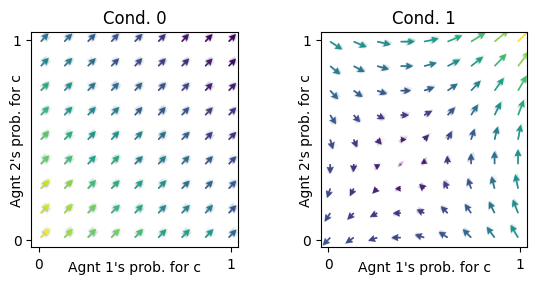

In [ ]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

## A distributional perspective
Discretize rewards into a finate set $\mathcal R = \{r_1, \dots, r_{n_r}\}$


### Discretization grid 

In [ ]:
#| export
def compute_discretization_grid(Rmin, # Minimum reward obtainable
                                Rmax, # Maximum reward obtainable
                                Nr # Number of bin
                                ) -> tuple: # Gridpoints, Width 
    gridpoints = np.linspace(Rmin, Rmax, Nr)
    width  = np.round(gridpoints[1] - gridpoints[0], 8)
    return gridpoints, width

We create a regular grid for discretizing the rewards the agent receives,

In [ ]:
gridpoints, width = compute_discretization_grid(env.R.min(), env.R.max(), 21)
gridpoints

array([-4.  , -3.65, -3.3 , -2.95, -2.6 , -2.25, -1.9 , -1.55, -1.2 ,
       -0.85, -0.5 , -0.15,  0.2 ,  0.55,  0.9 ,  1.25,  1.6 ,  1.95,
        2.3 ,  2.65,  3.  ])

with

In [ ]:
width

0.35

Illustrating the discretization grid graphically,

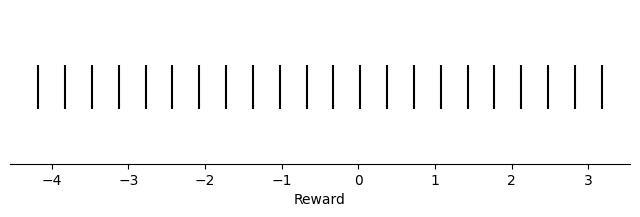

In [ ]:
plt.figure(figsize=(8,2))
plt.gca().spines[['right', 'top', 'left']].set_visible(False)
boundaries = np.array(list(gridpoints - width/2) + 
                      [gridpoints[-1] + width/2])
plt.scatter(boundaries, np.zeros_like(boundaries), marker="|", c='k', s=1000)
plt.yticks([]); plt.xlabel('Reward');

### Reward distribution

We assume (for now) that the environment has a deterministic reward function,
$$R^i(s, \boldsymbol a, s').$$
(Note: This could be extended to deal with environment that have stochastic rewards.)

Next, we transform the reward function into a reward distribution,
$$R^i(s, \boldsymbol a, s', r).$$

In [ ]:
#| export
def compute_Risjasr(env, # The env object
                    nr,  # The number of reward bins
                    discretization_sigma # Width of the discritization normal distribution
                   ) -> np.ndarray: # Reward distribution
    # get the discretization grid
    points, width = compute_discretization_grid(env.R.min(), env.R.max(), nr)

    # init the reward distribution tensor
    Risjasr = np.ones(env.R.shape + (nr,)) * -1  # last dim is distrib
        
    # scale the standard devision with the width of the discritization grid 
    sig = discretization_sigma*width

    # go through the reward tensor of the envrionment
    for index, _ in np.ndenumerate(env.R):
        valr = env.R[index]  # the actual environmental reward value 
        for r in range(nr):
            if r==0: # first interval
                prop = norm.cdf(points[r]+width/2, valr, sig)
            elif r==nr-1: # last interval
                prop = 1 - norm.cdf(points[r]-width/2, valr, sig)
            else: # all other intervals
                prop = norm.cdf(points[r]+width/2, valr, sig)\
                    - norm.cdf(points[r]-width/2, valr, sig)   
            Risjasr[index +(r,)] = prop

    return Risjasr

Testing the reward tensor distribution implementation,

In [ ]:
nr = 21
sig = 0.5
Risjasr = compute_Risjasr(env, nr, sig)
gpoints, wdth = compute_discretization_grid(env.R.min(), env.R.max(), nr)

def plot_Risjasr(i,s,a1,a2,s_, Rr=Risjasr,gpoints=gpoints,wdth=wdth):
    plt.figure(figsize=(8,3))
    plt.gca().spines[['right', 'top', 'left']].set_visible(False)
    plt.bar(gpoints, Rr[i,s,a1,a2,s_,:], width=0.95*wdth, color='k')
    rv = env.R[i,s,a1,a2,s_]
    plt.plot([rv, rv], [0.0, 0.05], c='red', lw=5)
    plt.xlabel("Reward");

For exampe, Agent zero's reward distribution in the prosperous state $s=0$, when both agents cooperate ($a=0$) and the envrionment remains in the prosperous state is 

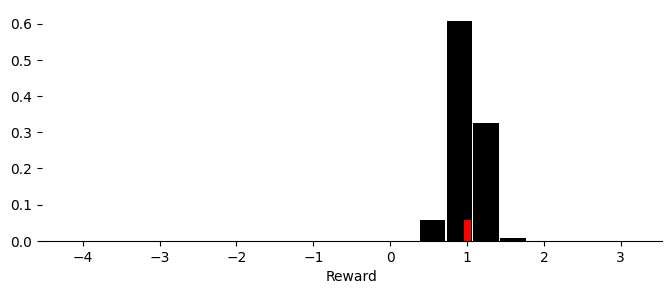

In [ ]:
plot_Risjasr(i=0,s=1,a1=0,a2=0,s_=1)

The red bar indicates the deterministic reward.

If the envrionment collapses, agents are pretty sure to get punsihed for it.

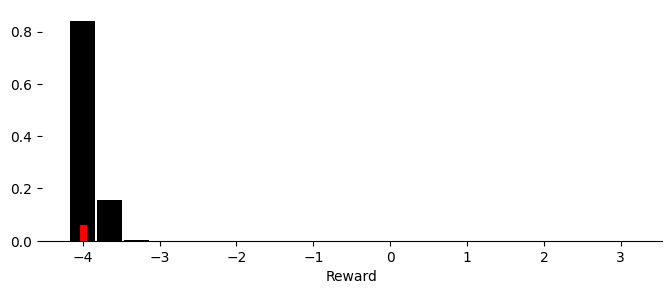

In [ ]:
plot_Risjasr(i=1,s=1,a1=0,a2=1,s_=0)

### Smoothed Bellman Kronecker $\delta_{vrv'}$ and $\delta_{dvrv'}$

The smoothed Bellman Kronecker delta allows us to compute the probability that (discretized) values $d$, $r$, $v$ and $v'$ satisfy the following relations:

* the Bellman equation $v = (1-\gamma)r + \gamma v'$
* the prediction error formula $d = (1-\gamma)r + \gamma v' - v$

The smoothed Bellman Kronecker deltas also allow for some uncertainty about the categorization into different bins. They are computed during agent initialization, and will be used later.

In [ ]:
#| export    
# Smoothed Bellman Kronecker delta for Bellman equation
def compute_b_ivrv_(env, # env object
                    nr, # number of bins
                    discretization_sigma, # width of discretization normal distribution
                    gamma # discount factor
                   ) -> np.ndarray: 
    
    points, width = compute_discretization_grid(env.R.min(), env.R.max(), nr)
    sigma = discretization_sigma * width
    b_ivrv_ = np.ones((env.N, nr, nr, nr)) * -1

    for v in range(nr):
        for r in range(nr):
            for v_ in range(nr):
                
                valv = (1 - gamma) * points[r] + gamma * points[v_]
                
                # gaussian distribution around valq with std `sig` 
                if v==0:
                    prop = norm.cdf(points[v]+width/2, valv, sigma)
                elif v==nr-1: # last intervall
                    prop = 1 - norm.cdf(points[v]-width/2, valv, sigma)
                else:
                    prop = norm.cdf(points[v]+width/2, 
                                    valv, sigma) - norm.cdf(points[v]-width/2, valv, sigma)
                    
                b_ivrv_[:,v,r,v_] = prop
    return b_ivrv_

In [ ]:
#| export
# Smoothed Bellman Kronecker delta for prediction error
def compute_b_idvrv_(env,
                     nr, 
                     discretization_sigma,
                     gamma
                    ) -> np.ndarray:
    points, width = compute_discretization_grid(env.R.min(), env.R.max(), nr)
    new_points = np.linspace(points.min() - points.max(), points.max() - points.min(), nr)
    new_width = new_points[1] - new_points[0]
    sigma = discretization_sigma * new_width
    b_idvrv_ = np.ones((env.N, nr, nr, nr, nr)) * -1

    for d in range(nr):
        for v in range(nr):
            for r in range(nr):
                for v_ in range(nr):
                
                    vald = (1-gamma)*points[r] + gamma*points[v_] - points[v] 
                
                    # gaussian distribution around valq with std `sig` 
                    if d==0:
                        prop = norm.cdf(new_points[d]+new_width/2, vald, sigma)
                    elif d==nr-1: # last intervall
                        prop = 1 - norm.cdf(new_points[d]-new_width/2, vald, sigma)
                    else:
                        prop = norm.cdf(new_points[d]+new_width/2, 
                                        vald, sigma) - norm.cdf(new_points[d]-new_width/2, vald, sigma)
                    
                    b_idvrv_[:,d,v,r,v_] = prop
    return b_idvrv_

### Initialize the agent class

In [ ]:
#| export
class distbase(abase):
    """
    Base class for deterministic strategy-average independent (multi-agent)
    temporal-difference reinforcement learning in strategy space.        
    """
    
    def __init__(self,
                 env, # An environment object
                 nr_reward_bins, # The number of bins to resolve rewards
                 discretization_sigma, # standard div for reward discretization
                 learning_rates, # agents' learning rates
                 discount_factors, # agents' discount factors
                 choice_intensities=1.0, # agents' choice intensities
                 opteinsum=True,  # optimize einsum functions
                 **kwargs):

        self.env = env
        Tt = env.T; assert np.allclose(Tt.sum(-1), 1)
        Rt = env.R 
        super().__init__(Tt, Rt, discount_factors, True, opteinsum)
        self.F = jnp.array(env.F)

        # learning rates
        self.alpha = make_variable_vector(learning_rates, self.N)

        # intensity of choice
        self.beta = make_variable_vector(choice_intensities, self.N)
        
        # discount factors
        self.gamma = make_variable_vector(discount_factors, self.N)
        
        # number of reward bins
        self.nr = nr_reward_bins
        
        # reward discretization deviation 
        self.discsig = discretization_sigma
        
        # discretization grid
        disc_grid = compute_discretization_grid(env.R.min(), env.R.max(), self.nr)
        self.gridpoints = disc_grid[0]
        self.gridwidth = disc_grid[1]
        
        # reward tensor distribution
        self.Rr = compute_Risjasr(env, self.nr, self.discsig)
        
        # Bellman ivrv_
        self.b_ivrv_ = compute_b_ivrv_(env, self.nr, self.discsig, self.gamma)
        
        # Bellman idvrv_
        self.b_idvrv_ = compute_b_idvrv_(env, self.nr, self.discsig, self.gamma)
        


In [ ]:
db = distbase(env,
              nr_reward_bins=21,
              discretization_sigma=0.25,
              learning_rates=0.1,
              discount_factors=0.9)

We define a distributional base agent with `db.nr` bins,

In [ ]:
db.nr

21

In [ ]:
db.discsig

0.25

In [ ]:
db.gridpoints

array([-4.  , -3.65, -3.3 , -2.95, -2.6 , -2.25, -1.9 , -1.55, -1.2 ,
       -0.85, -0.5 , -0.15,  0.2 ,  0.55,  0.9 ,  1.25,  1.6 ,  1.95,
        2.3 ,  2.65,  3.  ])

In [ ]:
db.gridwidth

0.35

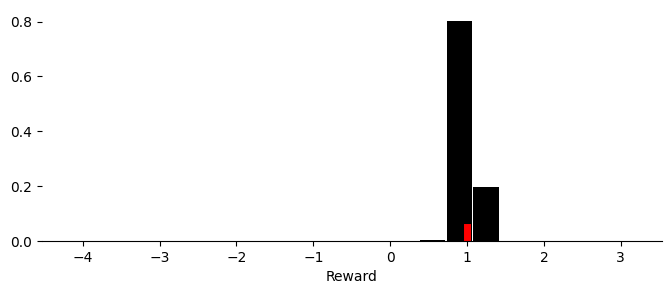

In [ ]:
plot_Risjasr(i=0,s=1,a1=0,a2=0,s_=1,
             Rr=db.Rr, gpoints=db.gridpoints, wdth=db.gridwidth)

### Reward distribution `Risr`

The first *core* method of the distributional RL agent will be `Risr`. This will compute the probability, that agent $i$ receives reward $r$ in state $s$,

$\bar R^i(s, r) = \sum_{s'}\sum_{a^i}\prod_{j} X^j(s, a^j) T(s, \boldsymbol a, s') R^i(s, \boldsymbol a, s', r).$

We will just-in-time (jit) compile this methods with jax.

In [ ]:
#| export
@partial(jit, static_argnums=0)    
def Risr(self:distbase, Xisa):
    i = 0; s = 1; sprim = 2; r=3; b2d = list(range(4, 4+self.N))
    Risjasr = jnp.array(self.Rr)
    
    X4einsum = list(it.chain(*zip(Xisa,
                            [[s, b2d[a]] for a in range(self.N)])))

    args = X4einsum + [env.T, [s]+b2d+[sprim],
                       Risjasr, [i, s]+b2d+[sprim, r], [i, s, r]]

    return jnp.einsum(*args, optimize=self.opti)

distbase.Risr = Risr  # Monkey-patching - possibly problematic?

Note, the monkey-patching example is from [python - fastai.fastcore patch decorator vs simple monkey-patching - Stack Overflow](https://stackoverflow.com/questions/73316102/fastai-fastcore-patch-decorator-vs-simple-monkey-patching). The problem is, that the patch decorator does not work with the `@partial(jit, ...)` decorator.

To compare the performance with jax-free version will also implement a `slow_Risr` method. However, we do so only here for profiling. It won't get exportet to the Python module.

In [ ]:
def slow_Risr(self:distbase, Xisa):
    i = 0; s = 1; sprim = 2; r=3; b2d = list(range(4, 4+self.N))
    Risjasr = np.array(self.Rr)
    
    X4einsum = list(it.chain(*zip(Xisa,
                            [[s, b2d[a]] for a in range(self.N)])))

    args = X4einsum + [env.T, [s]+b2d+[sprim],
                       Risjasr, [i, s]+b2d+[sprim, r], [i, s, r]]

    return np.einsum(*args, optimize=self.opti)

distbase.slow_Risr = slow_Risr  # Monkey-patching - possibly problematic?

Now we test both methods,

In [ ]:
db = distbase(env,
              nr_reward_bins=21,
              discretization_sigma=0.25,
              learning_rates=0.1,
              discount_factors=0.9)

with a random strategy,

In [ ]:
X = jnp.array(mae.random_softmax_strategy())

They should yield the same value,

In [ ]:
np.allclose(db.Risr(X), db.slow_Risr(X))

True

However, their performance is different,

In [ ]:
%timeit db.Risr(X)
%timeit db.slow_Risr(X)

5.38 µs ± 239 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
316 µs ± 71.3 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


Thus, with jit, this method is on this particular machine,

In [ ]:
212/4.57

46.389496717724285

times faster than the jax-free method!

Beyond compute performance, we illustrate the method by a plot,

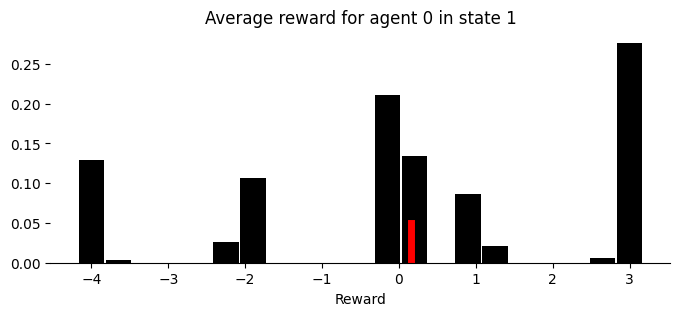

In [ ]:
def plot_Risr(i, s, Rr=Risr,gpoints=gpoints,wdth=wdth):
    plt.figure(figsize=(8,3))
    plt.gca().spines[['right', 'top', 'left']].set_visible(False)
    plt.bar(gpoints, Rr[i,s,:], width=0.95*wdth, color='k')
    ris = mae.Ris(X)[i,s]
    plt.plot([ris, ris], [0.0, 0.05], c='red', lw=5)
    plt.title("Average reward for agent "+str(i)+" in state "+str(s))
    plt.xlabel("Reward")

plot_Risr(i=0, s=1, Rr=db.Risr(X), gpoints=db.gridpoints, wdth=db.gridwidth)

What if one agent tends to cooperate in the prosperous environment, while the other tends to defect?

In [ ]:
X_cd = 0.5 * np.ones((2, 2, 2))
# Agent 0 cooperates
X_cd[0, 1, 0] = 0.95
X_cd[0, 1, 1] = 1 - X_cd[0, 1, 0]
# Agent 1 defects
X_cd[1, 1, 0] = 0.05
X_cd[1, 1, 1] = 1 - X_cd[1, 1, 0]

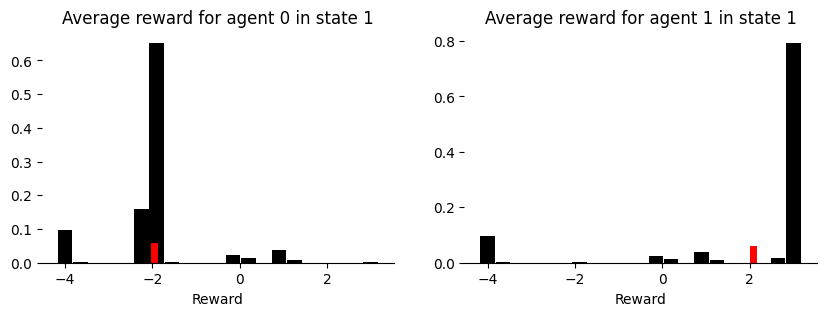

In [ ]:
def plot_R2sr(s, Rr=Risr,gpoints=gpoints,wdth=wdth):
    fig, axes = plt.subplots(1, 2, figsize=(10,3))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Rr[i,s,:], width=0.95*wdth, color='k')
        ris = mae.Ris(X_cd)[i,s]
        ax.plot([ris, ris], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("Reward")
        ax.set_title("Average reward for agent "+str(i)+" in state "+str(s))
    

plot_R2sr(s=1, Rr=db.Risr(X_cd), gpoints=db.gridpoints, wdth=db.gridwidth)

The cooperative agent has a high chance of getting exploited.

## Return distribution $\bar V^i(s, v)$
For $v, r, v' \in \mathcal R$, 

$$ 
V^i(s, v) =  \sum_{r, v', s'} \delta_{vrv'} R^i(s, r) \bar T(s, s') V^i(s', v')
$$

Summarizing

$$M^i(s, v, s', v') = \sum_r \delta(v, r, v') R^i(s, r) \bar T(s, s') $$

yields

$$ 
V^i(s, v) =  \sum_{v', s'} M^i(s, v, s', v') V^i(s', v').
$$

Now we can combine the indices $s \times v = w$ and have $V^i(w) = \sum_{w'} M(w, w') V^i(w')$ to realize that the return distribution should be found in the eigenvalues of the Bellman matrix $M$.

The smoothed Bellman Kronecker delta $\delta_{vrv'}$ was computed during agent initialization. Thus, we just need to define a method to obtain the double-matrix. 

### Double-matrix $M^{i}(s, v, s', v')$

In [ ]:
#| export
@partial(jit, static_argnums=0)    
def M_iww_(self:distbase, 
           Xisa  # Behavior profiles
          ) -> jnp.ndarray:
    Tss = self.Tss(Xisa)
    Risr = self.Risr(Xisa)
    b_ivrv_ = self.b_ivrv_

    i=0; v=1; r=2; v_=3; s=4; s_=5

    M = jnp.einsum(b_ivrv_, [i,v,r,v_], Risr, [i, s, r], Tss, 
                   [s, s_], [i, s, v_, s_, v], optimize=self.opti)
    jnp.allclose(M.sum((-2,-1)), 1.0)
    return M

distbase.M_iww_ = M_iww_  # Monkey-patching - possibly problematic?

Now we can obtain the return distribution $V^{i}(s,v)$.

In [ ]:
#| export
@partial(jit, static_argnums=0)
def Visv(self:distbase,
        Xisa  # Behavior profiles
        ) -> jnp.ndarray:
    M_iww_ = self.M_iww_(Xisa)
    Visv = jnp.ones((self.N, self.Z, self.nr)) * -1

    for i in range(self.N):
        mat = M_iww_[i].reshape(self.Z*self.nr, self.Z*self.nr)
        _pS = compute_stationarydistribution(mat)
        ix = jnp.max(jnp.where(_pS.mean(0)!=-10, jnp.arange(_pS.shape[0]), -1))
        pS = _pS[:, ix]
        
        Ps = pS.reshape(self.Z, self.nr).sum(-1)
        # assert jnp.allclose(self.Ps(Xisa), Ps, atol=1e-4)

        VIsv = pS.reshape(self.Z, self.nr) / pS.reshape(self.Z, self.nr).sum(-1, keepdims=True)
        
        Visv = Visv.at[i, ...].set(VIsv)

        # Visv[i, ...] = VIsv

    return Visv

distbase.Visv = Visv  # Monkey-patching - possibly problematic?

Plotting both agents' values in the prosperous state (with the cooperate/defect behavior profile $X_{cd}$):

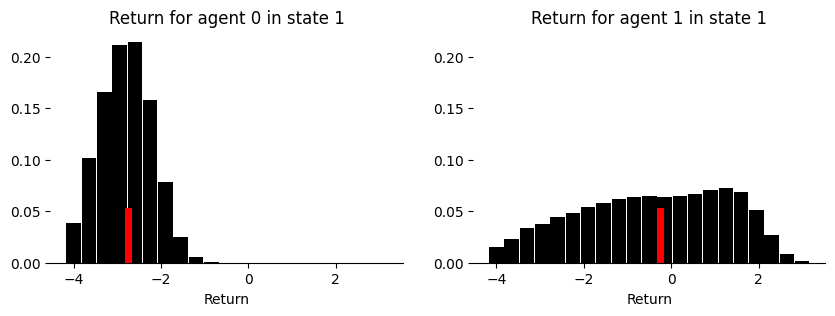

In [ ]:
def plot_V2sv(s, Vv=Visv,gpoints=gpoints,wdth=wdth):
    fig, axes = plt.subplots(1, 2, figsize=(10,3))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Vv[i,s,:], width=0.95*wdth, color='k')
        vis = mae.Vis(X_cd)[i,s]
        ax.plot([vis, vis], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("Return")
        ax.set_title("Return for agent "+str(i)+" in state "+str(s))
        ax.set_ylim([0, np.max(Vv[:,s,:])+0.01])
    

plot_V2sv(s=1, Vv=db.Visv(X_cd), gpoints=db.gridpoints, wdth=db.gridwidth)

## Next-state-action value $^{next}V^{i}(s, a, v)$

In the deterministic limit,

$$ ^{next}V^{i}(s, a) = \sum_{s'} \sum_{a^{-i}} X^{-i}(s,a^{-i}) T(s,a,a^{-i},s') V^{i}(s')(X) $$

In a distributional framework,

$$ ^{next}V^{i}(s, a, v) = \sum_{s'} \sum_{a^{-i}} X^{-i}(s,a^{-i}) T(s,a,a^{-i},s') V^{i}(s',v)(X) $$

In [ ]:
#| export
@partial(jit, static_argnums=0)
def nextVisav(self:distbase,
              Xisa  # Behavior profiles
             ) -> jnp.ndarray:
    
    Visv = self.Visv(Xisa)
    
    i = 0; a = 1; s = 2; s_ = 3; r = 4
    j2k = list(range(6, 6+self.N-1))  # other agents
    b2d = list(range(6+self.N-1, 6+self.N-1 + self.N))  # all actions
    e2f = list(range(5+2*self.N, 5+2*self.N + self.N-1))  # all other acts

    sumsis = [[j2k[l], s, e2f[l]] for l in range(self.N-1)]  # sum inds
    otherX = list(it.chain(*zip((self.N-1)*[Xisa], sumsis)))
                                
    args = [self.Omega, [i]+j2k+[a]+b2d+e2f] + otherX +\
        [self.T, [s]+b2d+[s_], Visv, [i, s_, r], [i, s, a, r]]
    
    nextVisav = jnp.einsum(*args, optimize=self.opti)

    return nextVisav

distbase.nextVisav = nextVisav  # Monkey-patching - possibly problematic?

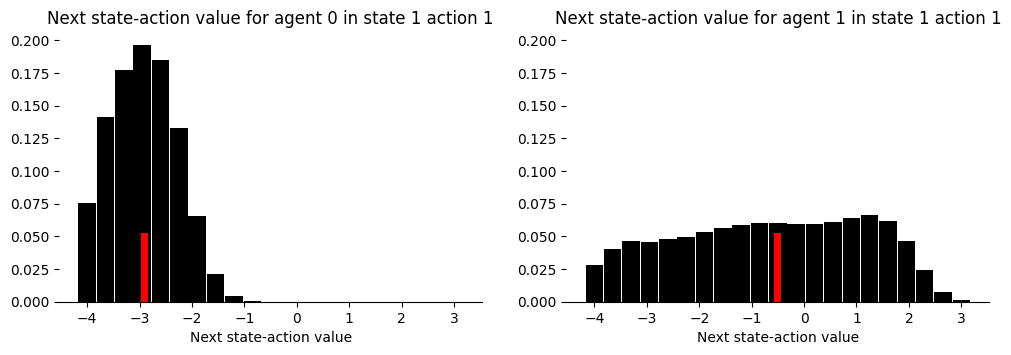

In [ ]:
def plot_nextV2sav(s, a, Vv=nextVisav, Xisa=X, gpoints=gpoints,wdth=wdth):
    fig, axes = plt.subplots(1, 2, figsize=(12,3.5))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Vv[i,s,a,:], width=0.95*wdth, color='k')
        nvisa = mae.NextVisa(Xisa)[i,s,a]
        ax.plot([nvisa, nvisa], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("Next state-action value")
        ax.set_title("Next state-action value for agent "+str(i)+" in state "+str(s)+" action "+str(a))
        ax.set_ylim([0, np.max(Vv[:,s,a,:])+0.01])
    

plot_nextV2sav(s=1, a=1, Vv=db.nextVisav(X_cd), Xisa=X_cd, gpoints=db.gridpoints, wdth=db.gridwidth)

## Prediction error $^{ac}D^{i}(s,a,d)$

For an actor-critic agent, the prediction error in the deterministic limit reads: 

$$ ^{ac}D^{i}(s,a)(t, \infty) = (1 - \gamma^{i}) _{TX^{-i}} \langle R^{i}(s,a) \rangle + \gamma^{i} .^{next}V^{i}(s, a)(X) $$ 

One can subtract the average return, but this does not change the dynamics.

In a distributional framework:

$$ ^{ac}D^{i}(s,a,d)(t, \infty) = \sum_{v,r,v'} \delta_{dvrv'} R^{i}(s,a,r) ^{next}V^{i}(s, a, v') V^{i}(s,v)$$ 

with $\delta_{dvrv'}$ the smoothed Bellman-Kronecker delta that makes sure the prediction-error formula is satisfied (defined at the beginning of this notebook).

As a first step, we need to compute the distribution of rewards $R^{i}(s,a,r)$.

In [ ]:
#| export
@partial(jit, static_argnums=0)
def Risar(self:distbase,
          Xisa  # Behavior profiles
         ) -> jnp.ndarray:
    
    i = 0; a = 1; s = 2; s_ = 3; r = 4  # Variables
    j2k = list(range(5, 5+self.N-1))  # other agents
    b2d = list(range(5+self.N-1, 5+self.N-1 + self.N))  # all actions
    e2f = list(range(4+2*self.N, 4+2*self.N + self.N-1))  # all other acts
    Risjasr = self.Rr
 
    sumsis = [[j2k[l], s, e2f[l]] for l in range(self.N-1)]  # sum inds
    otherX = list(it.chain(*zip((self.N-1)*[Xisa], sumsis)))

    args = [self.Omega, [i]+j2k+[a]+b2d+e2f] + otherX\
        + [self.T, [s]+b2d+[s_], Risjasr, [i, s]+b2d+[s_, r],
            [i, s, a, r]]
    Risar = jnp.einsum(*args, optimize=mae.opti)
    return Risar

distbase.Risar = Risar # Monkey-patching - possibly problematic?

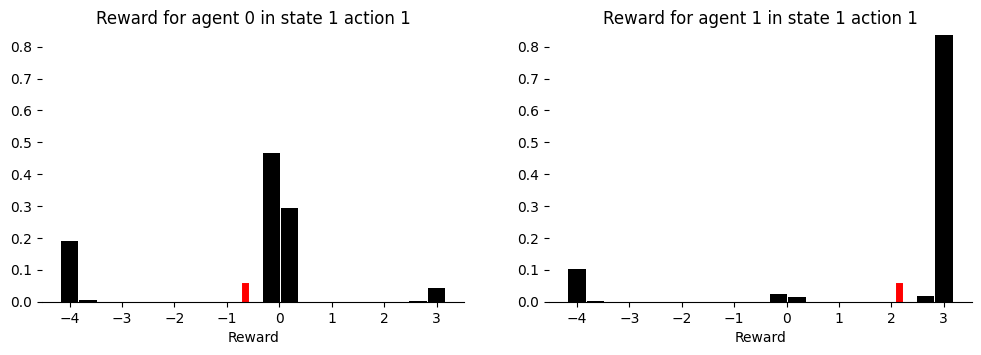

In [ ]:
def plot_R2sar(s, a, Rr=Risar, Xisa=X, gpoints=gpoints,wdth=wdth):
    fig, axes = plt.subplots(1, 2, figsize=(12,3.5))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Rr[i,s,a,:], width=0.95*wdth, color='k')
        risa = mae.Risa(Xisa)[i,s,a]
        ax.plot([risa, risa], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("Reward")
        ax.set_title("Reward for agent "+str(i)+" in state "+str(s)+" action "+str(a))
        ax.set_ylim([0, np.max(Rr[:,s,a,:])+0.01])
    

plot_R2sar(s=1, a=1, Rr=db.Risar(X_cd), Xisa=X_cd, gpoints=db.gridpoints, wdth=db.gridwidth)

Now, we have all the ingredients needed to compute the prediction error distribution.

In [ ]:
#| export
@partial(jit, static_argnums=0)
def Disad(self:distbase,
          Xisa  # Behavior profiles
         ) -> jnp.ndarray:
    # Compute needed tensors
    Risar = self.Risar(Xisa)
    Visv = self.Visv(Xisa)
    nextVisav = self.nextVisav(Xisa)
    # Reformat Visv
    Visav = jnp.zeros((2, 2, 2, db.nr))
    Visav = Visav.at[:, :, 0, :].set(Visv)
    Visav = Visav.at[:, :, 1, :].set(Visv)

    b_idvrv_ = self.b_idvrv_

    i=0; d=1; v=2; r=3; v_=4; s=5; a=6; s_=7

    Disad = jnp.einsum(b_idvrv_, [i,d,v,r,v_], Risar, [i,s,a,r], nextVisav, [i,s,a,v_], 
                      Visav, [i,s,a,v], [i, s, a, d])
    return Disad

distbase.Disad = Disad

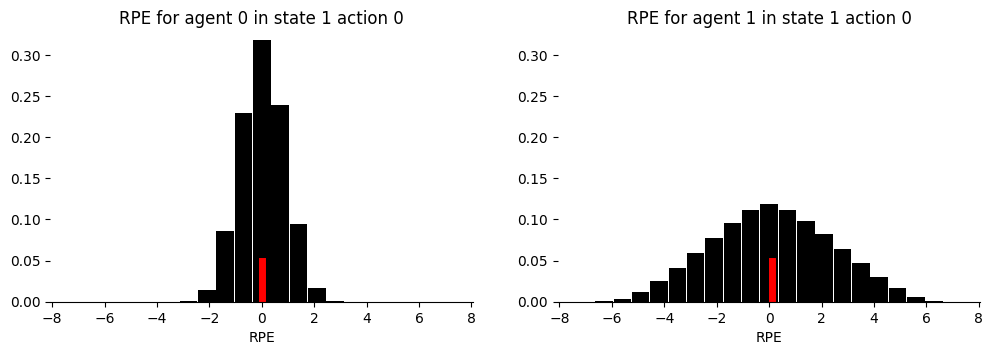

In [ ]:
def plot_D2sad(s, a, Dd=Disad, Xisa=X, gpoints=gpoints,wdth=wdth):
    newpoints = np.linspace(gpoints.min() - gpoints.max(), gpoints.max() - gpoints.min(), db.nr)
    newwidth = np.round(newpoints[1] - newpoints[0], 8)
    fig, axes = plt.subplots(1, 2, figsize=(12,3.5))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(newpoints, Dd[i,s,a,:], width=0.95*newwidth, color='k')
        disa = mae.RPEisa(Xisa)[i,s,a]
        ax.plot([disa, disa], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("RPE")
        ax.set_title("RPE for agent "+str(i)+" in state "+str(s)+" action "+str(a))
        ax.set_ylim([0, np.max(Dd[:,s,a,:])+0.01])
    

plot_D2sad(s=1, a=0, Dd=db.Disad(X_cd), Xisa=X_cd, gpoints=db.gridpoints, wdth=db.gridwidth)

The defecting agent is more likely to be surprised than the cooperating agent. This reflects the gap between doing well in the prosperous state (where the defecting agent exploits the cooperating one), and doing poorly in the degraded state (where all agents get a punishment of $-4$).

------

In [ ]:
nbdev.export.nb_export("DistLD.ipynb", "")